In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

df = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv')
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


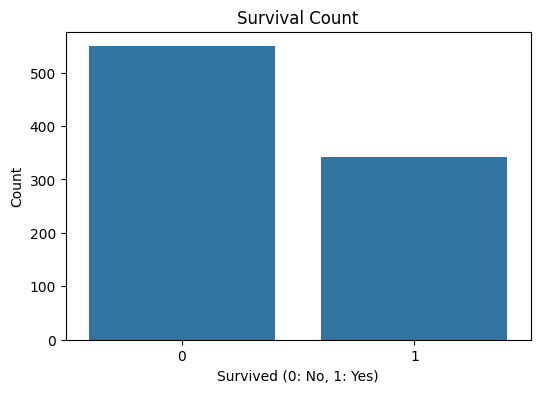

In [ ]:
from matplotlib import pyplot as plt
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="survived")
plt.title("Survival Count")
plt.xlabel("Survived (0: No, 1: Yes)")
plt.ylabel("Count")
plt.show()

            survived    pclass       age     sibsp     parch      fare  \
survived    1.000000 -0.338481 -0.077221 -0.035322  0.081629  0.257307   
pclass     -0.338481  1.000000 -0.369226  0.083081  0.018443 -0.549500   
age        -0.077221 -0.369226  1.000000 -0.308247 -0.189119  0.096067   
sibsp      -0.035322  0.083081 -0.308247  1.000000  0.414838  0.159651   
parch       0.081629  0.018443 -0.189119  0.414838  1.000000  0.216225   
fare        0.257307 -0.549500  0.096067  0.159651  0.216225  1.000000   
adult_male -0.557080  0.094035  0.280328 -0.253586 -0.349943 -0.182024   
alone      -0.203367  0.135207  0.198270 -0.584471 -0.583398 -0.271832   

            adult_male     alone  
survived     -0.557080 -0.203367  
pclass        0.094035  0.135207  
age           0.280328  0.198270  
sibsp        -0.253586 -0.584471  
parch        -0.349943 -0.583398  
fare         -0.182024 -0.271832  
adult_male    1.000000  0.404744  
alone         0.404744  1.000000  


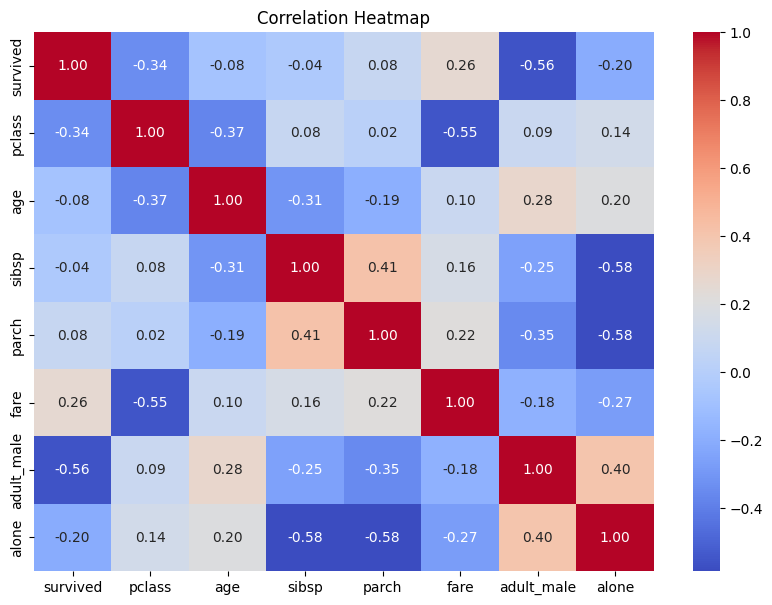

In [ ]:
# 상관관계 시각화
correlation = df.corr(numeric_only=True)
print(correlation)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [ ]:
df['embark_town'].value_counts()

,count
embark_town,
Southampton,644
Cherbourg,168
Queenstown,77


In [ ]:
# sex를 정수 범주로 변환하고 embarked, embarked_town이 nan인 행을 제거
del df['alive']
del df['adult_male']
df['sex'] = df['sex'].map({'male' : 0, 'female' : 1})
df.dropna(subset=['embarked'])
df.dropna(subset=['embark_town'])
df['embarked'] = df['embarked'].map({'C' : 0, 'Q' : 1, 'S' : 2})
df['deck'] = df['deck'].fillna('Unknown')

df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,deck,embark_town,alone
0,0,3,0,22.0,1,0,7.2500,2.0,Third,man,Unknown,Southampton,False
1,1,1,1,38.0,1,0,71.2833,0.0,First,woman,C,Cherbourg,False
2,1,3,1,26.0,0,0,7.9250,2.0,Third,woman,Unknown,Southampton,True
3,1,1,1,35.0,1,0,53.1000,2.0,First,woman,C,Southampton,False
4,0,3,0,35.0,0,0,8.0500,2.0,Third,man,Unknown,Southampton,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,27.0,0,0,13.0000,2.0,Second,man,Unknown,Southampton,True
887,1,1,1,19.0,0,0,30.0000,2.0,First,woman,B,Southampton,True
888,0,3,1,NaN,1,2,23.4500,2.0,Third,woman,Unknown,Southampton,False
889,1,1,0,26.0,0,0,30.0000,0.0,First,man,C,Cherbourg,True


In [ ]:
from sklearn.model_selection import train_test_split
X, y = df.iloc[:, 1:], df.iloc[:, 0]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=0, stratify=y)

In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy = "mean")
X_train['age'] = imputer.fit_transform(X_train[['age']])
X_test['age'] = imputer.transform(X_test[['age']])
X_test

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,deck,embark_town,alone
421,3,0,21.000000,0,0,7.7333,1.0,Third,man,Unknown,Queenstown,True
618,2,1,4.000000,2,1,39.0000,2.0,Second,child,F,Southampton,False
116,3,0,70.500000,0,0,7.7500,1.0,Third,man,Unknown,Queenstown,True
310,1,1,24.000000,0,0,83.1583,0.0,First,woman,C,Cherbourg,True
57,3,0,28.500000,0,0,7.2292,0.0,Third,man,Unknown,Cherbourg,True
...,...,...,...,...,...,...,...,...,...,...,...,...
653,3,1,29.526048,0,0,7.8292,1.0,Third,woman,Unknown,Queenstown,True
500,3,0,17.000000,0,0,8.6625,2.0,Third,man,Unknown,Southampton,True
512,1,0,36.000000,0,0,26.2875,2.0,First,man,E,Southampton,True
758,3,0,34.000000,0,0,8.0500,2.0,Third,man,Unknown,Southampton,True


In [ ]:
from sklearn.preprocessing import LabelEncoder

non_numeric_features = ['embarked', 'deck', 'class', 'who', 'embark_town', 'alone']

le =  LabelEncoder()
for feature in non_numeric_features:
  X_train[feature] = le.fit_transform(X_train[feature])
  X_test[feature] = le.transform(X_test[feature])
X_train

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,deck,embark_town,alone
231,3,0,29.000000,0,0,7.7750,2,2,1,7,2,1
836,3,0,21.000000,0,0,8.6625,2,2,1,7,2,1
639,3,0,29.526048,1,0,16.1000,2,2,1,7,2,0
389,2,1,17.000000,0,0,12.0000,0,1,2,7,0,1
597,3,0,49.000000,0,0,0.0000,2,2,1,7,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...
131,3,0,20.000000,0,0,7.0500,2,2,1,7,2,1
490,3,0,29.526048,1,0,19.9667,2,2,1,7,2,0
838,3,0,32.000000,0,0,56.4958,2,2,1,7,2,1
48,3,0,29.526048,2,0,21.6792,0,2,1,7,0,0


In [ ]:
from sklearn.preprocessing import StandardScaler
stdSc = StandardScaler()
X_train_std = stdSc.fit_transform(X_train)
X_test_std = stdSc.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train_std, y_train)
y_pred = lr.predict(X_test_std)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
---------------------------------------------------------------------------
ValueError                                Traceback (most recent call last)
/tmp/ipykernel_438/1771340573.py in <cell line: 0>()
      3 s = StandardScaler()
      4 X_train_s = s.fit_transform(X_train)
----> 5 y_train_s = s.transform(y_train)
      6 y_train_s

3 frames
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py in check_array(array, accept_sparse, accept_large_sparse, dtype, order, copy, force_writeable, force_all_finite, ensure_all_finite, ensure_non_negative, ensure_2d, allow_nd, ensure_min_samples, ensure_min_features, estimator, input_name)
   1091                         "if it contains a single sample."
   1092                     )
-> 1093                 raise ValueError(msg)
   1094
   1095         if dtype_numeric and hasattr(array.dtype, "kind") and array.dtype.kind in "USV":

ValueError: Expected a 2-dimensional container but got <class 'pandas.core.series.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

훈련 정확도: 0.7993579454253612
테스트 정확도: 0.8134328358208955


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print('Accuracy:', accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 0.8134328358208955
              precision    recall  f1-score   support

           0       0.82      0.89      0.85       165
           1       0.80      0.69      0.74       103

    accuracy                           0.81       268
   macro avg       0.81      0.79      0.80       268
weighted avg       0.81      0.81      0.81       268

